# Soil sand content (COG) — raw vs STAC folder vs cloud

Checks that the six sand depth rasters (sand_5km_0-5cm, sand_5km_5-15cm, sand_5km_15-30cm, sand_5km_30-60cm, sand_5km_60-100cm, sand_5km_100-200cm) are the same in the three places they live:

1. **Raw**: `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\<name>.tif` (original GeoTIFFs, `float64`)
2. **STAC folder**: `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\soil_sand_cog\cog\<name>.tif` (COGs produced by `notebooks/28_soil_sand_cog.ipynb`, `float32`)
3. **Cloud**: the COGs found through the public STAC catalog (`gca-stac-7`, collection `soil_sand_cog`)

The rasters are plotted side by side and compared pixel by pixel on valid pixels (the raw files mark empty cells as `NaN`, the COGs use `-9999`; raw values are compared after the `float64` to `float32` cast). The last sections show the six depth items as a `(depth, y, x)` cube (z-slices) and the WMS layers in GeoServer.

Environment: `environment_exploration.yml` (Miniforge).

In [9]:
import time
from pathlib import Path
from posixpath import join as urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pystac_client
import rasterio

## 1) Locations

In [10]:
data_vivian = Path(r"P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian")
names = ['sand_5km_0-5cm', 'sand_5km_5-15cm', 'sand_5km_15-30cm', 'sand_5km_30-60cm', 'sand_5km_60-100cm', 'sand_5km_100-200cm']
raw_paths = {n: data_vivian / f"{n}.tif" for n in names}
stac_folder_paths = {n: data_vivian / "stac" / "soil_sand_cog" / "cog" / f"{n}.tif" for n in names}

gcs_protocol = "https://storage.googleapis.com"
catalog_url = urljoin(gcs_protocol, "gca-data-public", "gca", "gca-stac-7", "catalog.json")
collection_id = "soil_sand_cog"

for p in (*raw_paths.values(), *stac_folder_paths.values()):
    print(p.is_file(), p)

True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_0-5cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_5-15cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_15-30cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_30-60cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_60-100cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_100-200cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\soil_sand_cog\cog\sand_5km_0-5cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\soil_sand_cog\cog\sand_5km_5-15cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\soil_sand_cog\cog\sand_5km_15-30cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\

## 2) Find the data through the STAC catalog

In [11]:
# public objects are cached for 1 h: a query string forces a fresh copy of catalog.json
catalog = pystac_client.Client.open(f"{catalog_url}?nocache={time.time()}")
# get_collection() can return another collection on a static catalog: match the id explicitly
collection = next((c for c in catalog.get_children() if c.id == collection_id), None)
if collection is None:
    raise LookupError(f"Collection {collection_id} not found in {catalog_url}")

items = {i.id: i for i in collection.get_items()}
print("Collection:", collection.id, "|", collection.title)
print("Items:", list(items))

cloud_hrefs = {}
for n in names:
    item = items[n]
    cloud_hrefs[n] = item.assets["data"].href
    assert collection_id in cloud_hrefs[n], f"Unexpected href: {cloud_hrefs[n]}"
    print(f"{n}: depth {item.properties.get('soil:depth_range')} | {cloud_hrefs[n]}")
    print("   raster bands:", item.assets["data"].extra_fields.get("raster:bands"))

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\client.py:191: NoConformsTo: Server does not advertise any conformance classes.
  warnings.warn(NoConformsTo())


Collection: soil_sand_cog | SoilGrids250m 2.0 - Sand content
Items: ['sand_5km_0-5cm', 'sand_5km_5-15cm', 'sand_5km_15-30cm', 'sand_5km_30-60cm', 'sand_5km_60-100cm', 'sand_5km_100-200cm']
sand_5km_0-5cm: depth 0-5 cm | https://storage.googleapis.com/gca-data-public/gca/soil_sand_cog/sand_5km_0-5cm.tif
   raster bands: [{'nodata': -9999.0, 'data_type': 'float32', 'spatial_resolution': 0.0449, 'unit': '%'}]
sand_5km_5-15cm: depth 5-15 cm | https://storage.googleapis.com/gca-data-public/gca/soil_sand_cog/sand_5km_5-15cm.tif
   raster bands: [{'nodata': -9999.0, 'data_type': 'float32', 'spatial_resolution': 0.0449, 'unit': '%'}]
sand_5km_15-30cm: depth 15-30 cm | https://storage.googleapis.com/gca-data-public/gca/soil_sand_cog/sand_5km_15-30cm.tif
   raster bands: [{'nodata': -9999.0, 'data_type': 'float32', 'spatial_resolution': 0.0449, 'unit': '%'}]
sand_5km_30-60cm: depth 30-60 cm | https://storage.googleapis.com/gca-data-public/gca/soil_sand_cog/sand_5km_30-60cm.tif
   raster bands: [

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\collection_client.py:149: FallbackToPystac: Falling back to pystac. This might be slow.
  root._warn_about_fallback("ITEM_SEARCH")


## 3) Read the rasters

In [12]:
sources = {
    n: {"raw (P:)": str(raw_paths[n]), "stac folder (P:)": str(stac_folder_paths[n]), "cloud (catalog)": cloud_hrefs[n]}
    for n in names
}

arrays, profiles = {}, {}
for n, srcs in sources.items():
    for label, path in srcs.items():
        with rasterio.open(path) as src:
            data = src.read(1).astype("float32").astype("float64")  # raw is float64, the COGs float32
            # Valid = finite and not the file's own nodata (raw files use different nodata values)
            valid = np.isfinite(data)
            if src.nodata is not None:
                valid &= ~np.isclose(data, src.nodata)
            arrays[(n, label)] = np.where(valid, data, np.nan)
            profiles[(n, label)] = {
                "shape": src.shape,
                "dtype": src.dtypes[0],
                "nodata": src.nodata,
                "crs": src.crs.to_string(),
                "transform": tuple(round(v, 6) for v in src.transform)[:6],
                "tiled (COG)": src.is_tiled,
                "overviews": src.overviews(1),
                "compression": str(src.compression),
                "bounds": tuple(round(v, 3) for v in src.bounds),
                "valid pixels": int(valid.sum()),
            }

pd.DataFrame(profiles).T

shape    dtype  nodata        crs  \
sand_5km_0-5cm     raw (P:)          (2076, 1671)  float64    None  EPSG:4326   
                   stac folder (P:)  (2076, 1671)  float32 -9999.0  EPSG:4326   
                   cloud (catalog)   (2076, 1671)  float32 -9999.0  EPSG:4326   
sand_5km_5-15cm    raw (P:)          (2076, 1671)  float64    None  EPSG:4326   
                   stac folder (P:)  (2076, 1671)  float32 -9999.0  EPSG:4326   
                   cloud (catalog)   (2076, 1671)  float32 -9999.0  EPSG:4326   
sand_5km_15-30cm   raw (P:)          (2076, 1671)  float64    None  EPSG:4326   
                   stac folder (P:)  (2076, 1671)  float32 -9999.0  EPSG:4326   
                   cloud (catalog)   (2076, 1671)  float32 -9999.0  EPSG:4326   
sand_5km_30-60cm   raw (P:)          (2076, 1671)  float64    None  EPSG:4326   
                   stac folder (P:)  (2076, 1671)  float32 -9999.0  EPSG:4326   
                   cloud (catalog)   (2076, 1671)  float32 -9999.0  EPSG:4326   
sand_5km_60-100cm  raw (P:)          (2076, 1671)  float64    None  EPSG:4326   
                   stac folder (P:)  (2076, 1671)  float32 -9999.0  EPSG:4326   
                   cloud (catalog)   (2076, 1671)  float32 -9999.0  EPSG:4326   
sand_5km_100-200cm raw (P:)          (2076, 1671)  float64    None  EPSG:4326   
                   stac folder (P:)  (2076, 1671)  float32 -9999.0  EPSG:4326   
                   cloud (catalog)   (2076, 1671)  float32 -9999.0  EPSG:4326   

                                                                             transform  \
sand_5km_0-5cm     raw (P:)          (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   stac folder (P:)  (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   cloud (catalog)   (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
sand_5km_5-15cm    raw (P:)          (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   stac folder (P:)  (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   cloud (catalog)   (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
sand_5km_15-30cm   raw (P:)          (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   stac folder (P:)  (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   cloud (catalog)   (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
sand_5km_30-60cm   raw (P:)          (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   stac folder (P:)  (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   cloud (catalog)   (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
sand_5km_60-100cm  raw (P:)          (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   stac folder (P:)  (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   cloud (catalog)   (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
sand_5km_100-200cm raw (P:)          (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   stac folder (P:)  (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   
                   cloud (catalog)   (0.044916, 0.0, -20.032431, 0.0, -0.044916, 46...   

                                    tiled (COG)  overviews  \
sand_5km_0-5cm     raw (P:)                True         []   
                   stac folder (P:)        True  [2, 4, 8]   
                   cloud (catalog)         True  [2, 4, 8]   
sand_5km_5-15cm    raw (P:)                True         []   
                   stac folder (P:)        True  [2, 4, 8]   
                   cloud (catalog)         True  [2, 4, 8]   
sand_5km_15-30cm   raw (P:)                True         []   
                   stac folder (P:)        True  [2, 4, 8]   
                   cloud (catalog)         True  [2, 4, 8]   
sand_5km_30-60cm   raw (P:)                True         []   
                   stac folder (P:)        True  [2, 4, 8]   
                   cloud (catalog)         True  

## 4) Plot

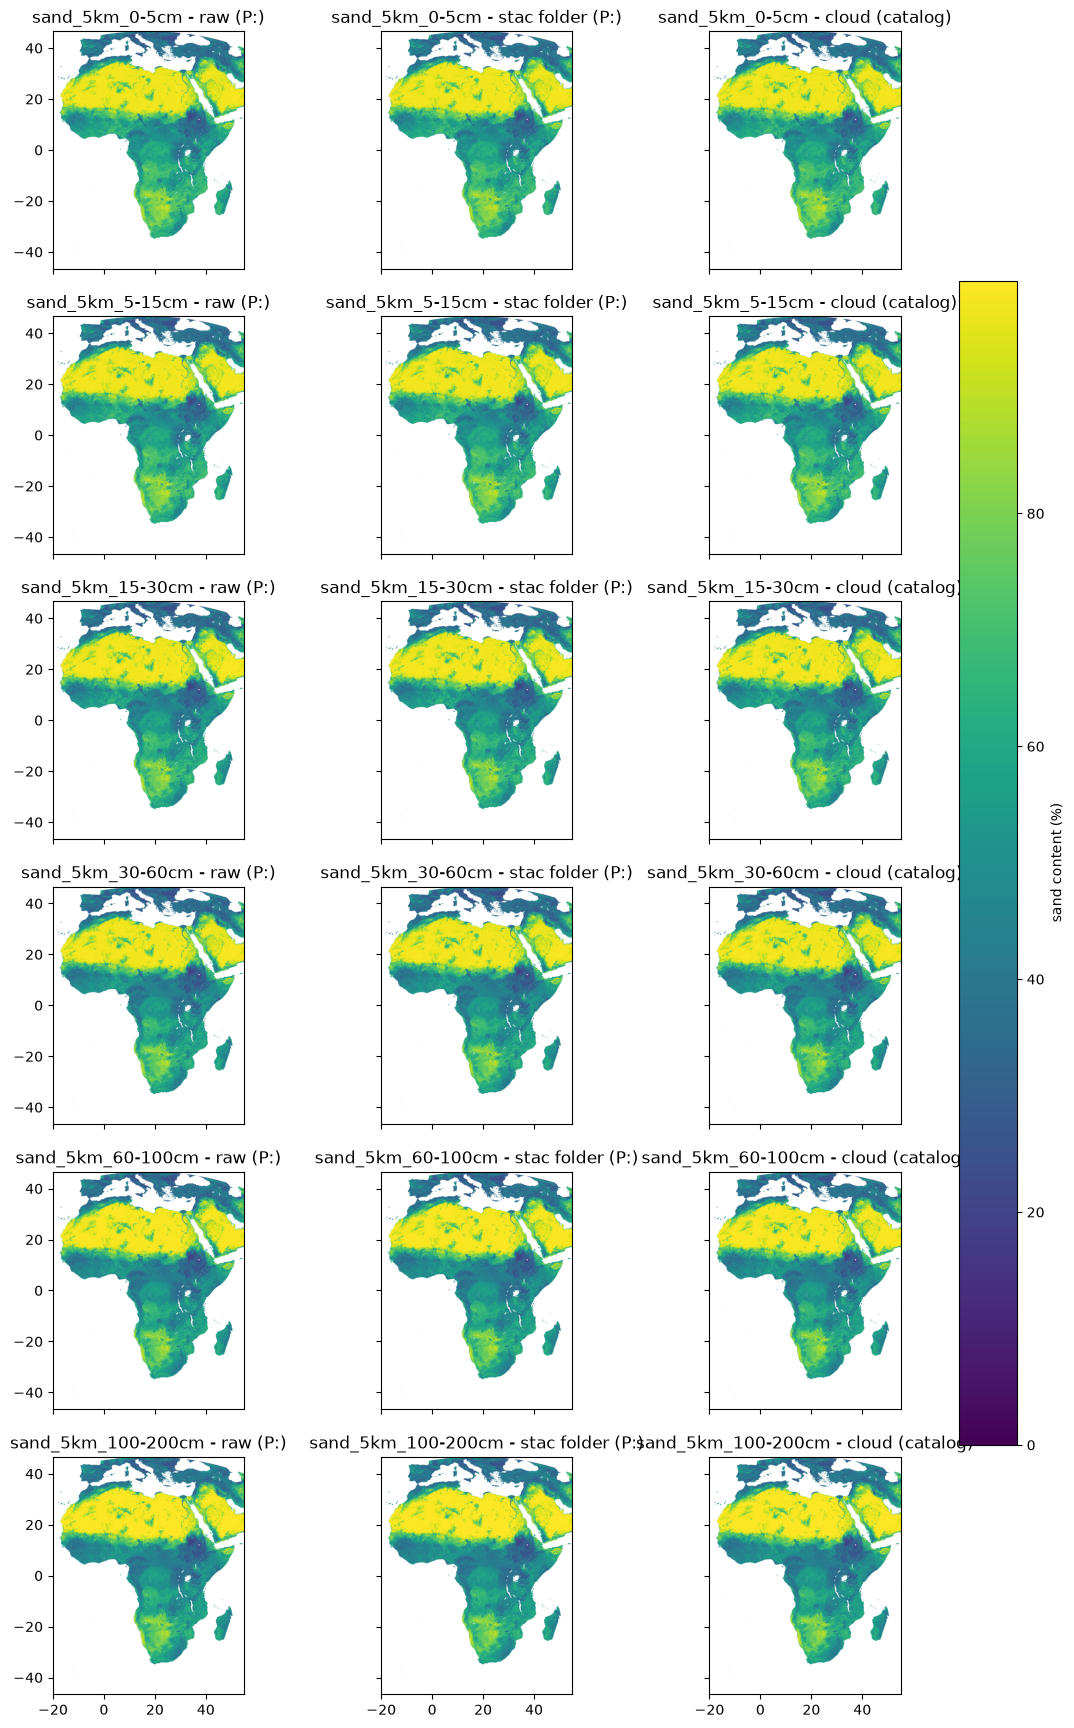

In [13]:
# Same colour scale for all panels so they can be compared by eye
vmax = float(np.nanpercentile(np.concatenate([a[~np.isnan(a)] for a in arrays.values()]), 99))
labels = list(sources[names[0]])

fig, axes = plt.subplots(len(names), len(labels), figsize=(5 * len(labels), 3.6 * len(names)), sharex=True, sharey=True)
for r, n in enumerate(names):
    for c, label in enumerate(labels):
        b = profiles[(n, label)]["bounds"]
        im = axes[r, c].imshow(arrays[(n, label)], cmap="viridis", vmin=0, vmax=vmax, extent=(b[0], b[2], b[1], b[3]))
        axes[r, c].set_title(f"{n} - {label}")
fig.colorbar(im, ax=axes, label="sand content (%)", shrink=0.7)
plt.show()

## 5) Compare

In [14]:
results = []
ref = labels[0]
for n in names:
    a = arrays[(n, ref)]
    for other in labels[1:]:
        b = arrays[(n, other)]
        same_shape = a.shape == b.shape
        same_mask = same_shape and np.array_equal(np.isnan(a), np.isnan(b))
        n_diff = int((a[~np.isnan(a)] != b[~np.isnan(a)]).sum()) if same_mask else None
        results.append({
            "item": n,
            "comparison": f"{ref} vs {other}",
            "same shape": same_shape,
            "same CRS/transform": (profiles[(n, ref)]["crs"], profiles[(n, ref)]["transform"]) == (profiles[(n, other)]["crs"], profiles[(n, other)]["transform"]),
            "same valid mask": same_mask,
            "different valid pixels": n_diff,
            "identical": bool(same_mask and n_diff == 0),
        })
display(pd.DataFrame(results))

if all(r["identical"] for r in results):
    print("OK: raw, stac folder and cloud contain exactly the same data.")
else:
    print("MISMATCH: see the table above.")

,item,comparison,same shape,same CRS/transform,same valid mask,different valid pixels,identical
0,sand_5km_0-5cm,raw (P:) vs stac folder (P:),True,True,True,0,True
1,sand_5km_0-5cm,raw (P:) vs cloud (catalog),True,True,True,0,True
2,sand_5km_5-15cm,raw (P:) vs stac folder (P:),True,True,True,0,True
3,sand_5km_5-15cm,raw (P:) vs cloud (catalog),True,True,True,0,True
4,sand_5km_15-30cm,raw (P:) vs stac folder (P:),True,True,True,0,True
5,sand_5km_15-30cm,raw (P:) vs cloud (catalog),True,True,True,0,True
6,sand_5km_30-60cm,raw (P:) vs stac folder (P:),True,True,True,0,True
7,sand_5km_30-60cm,raw (P:) vs cloud (catalog),True,True,True,0,True
8,sand_5km_60-100cm,raw (P:) vs stac folder (P:),True,True,True,0,True
9,sand_5km_60-100cm,raw (P:) vs cloud (catalog),True,True,True,0,True


OK: raw, stac folder and cloud contain exactly the same data.


## 6) The depth items as a cube

The six COGs are six items, but they share one grid, so they can be stacked into a `(depth, y, x)` cube in memory (the COG counterpart of the Zarr variant `30_soil_sand_zarr.ipynb`). Depth is the middle of each interval in cm.

('depth', 'y', 'x') (6, 2076, 1671)


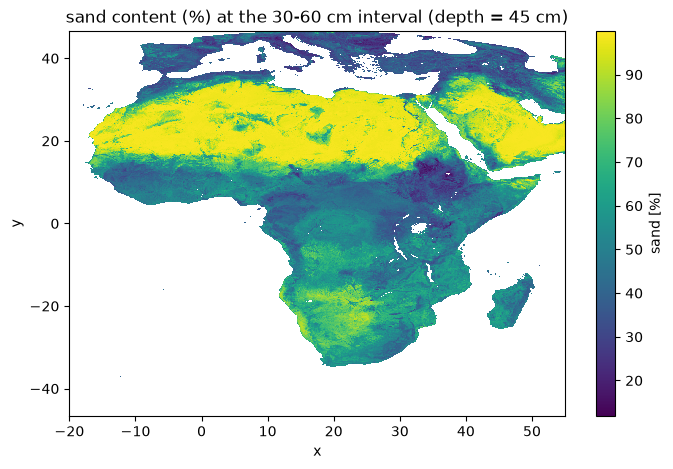

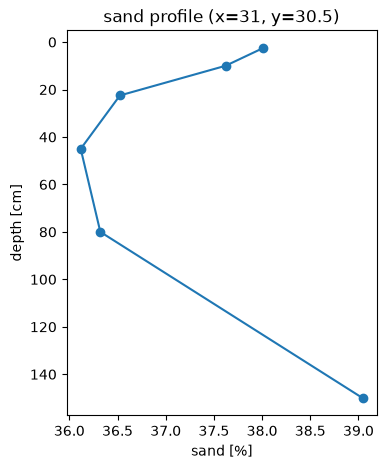

In [15]:
import xarray as xr

depth_mid = {n: (items[n].properties["soil:depth_top_cm"] + items[n].properties["soil:depth_bottom_cm"]) / 2 for n in names}
b = profiles[(names[0], "cloud (catalog)")]["bounds"]
ny, nx = arrays[(names[0], "cloud (catalog)")].shape
cube = xr.DataArray(
    np.stack([arrays[(n, "cloud (catalog)")] for n in names]),
    dims=("depth", "y", "x"),
    coords={
        "depth": list(depth_mid.values()),
        "y": b[3] - (np.arange(ny) + 0.5) * (b[3] - b[1]) / ny,
        "x": b[0] + (np.arange(nx) + 0.5) * (b[2] - b[0]) / nx,
    },
    name="sand",
    attrs={"units": "%"},
)
cube.coords["depth"].attrs.update(units="cm", positive="down")
print(cube.dims, cube.shape)

# z-slice: one depth over the whole grid
cube.sel(depth=45.0).plot(cmap="viridis", figsize=(8, 5))
plt.title("sand content (%) at the 30-60 cm interval (depth = 45 cm)")
plt.show()

# profile along depth at one point
point = cube.sel(x=31.0, y=30.5, method="nearest")
point.plot(y="depth", yincrease=False, marker="o", figsize=(4, 5))
plt.title("sand profile (x=31, y=30.5)")
plt.show()

## 7) Call the WMS service

Requests the six layers published in GeoServer (step 8 of `scripts/28_soil_sand_cog.ipynb`) through the `visual` asset of the STAC items, to check the service shows the same data. Needs access to the Deltares network. Colours come from the GeoServer style, so they will differ from the plots above.

WMS asset: https://international-delta-platform.avi.directory.intra/geoserver/wms/soil_sand_cog | layer: soil_sand_cog:sand_5km_0-5cm
WMS asset: https://international-delta-platform.avi.directory.intra/geoserver/wms/soil_sand_cog | layer: soil_sand_cog:sand_5km_5-15cm
WMS asset: https://international-delta-platform.avi.directory.intra/geoserver/wms/soil_sand_cog | layer: soil_sand_cog:sand_5km_15-30cm
WMS asset: https://international-delta-platform.avi.directory.intra/geoserver/wms/soil_sand_cog | layer: soil_sand_cog:sand_5km_30-60cm
WMS asset: https://international-delta-platform.avi.directory.intra/geoserver/wms/soil_sand_cog | layer: soil_sand_cog:sand_5km_60-100cm
WMS asset: https://international-delta-platform.avi.directory.intra/geoserver/wms/soil_sand_cog | layer: soil_sand_cog:sand_5km_100-200cm


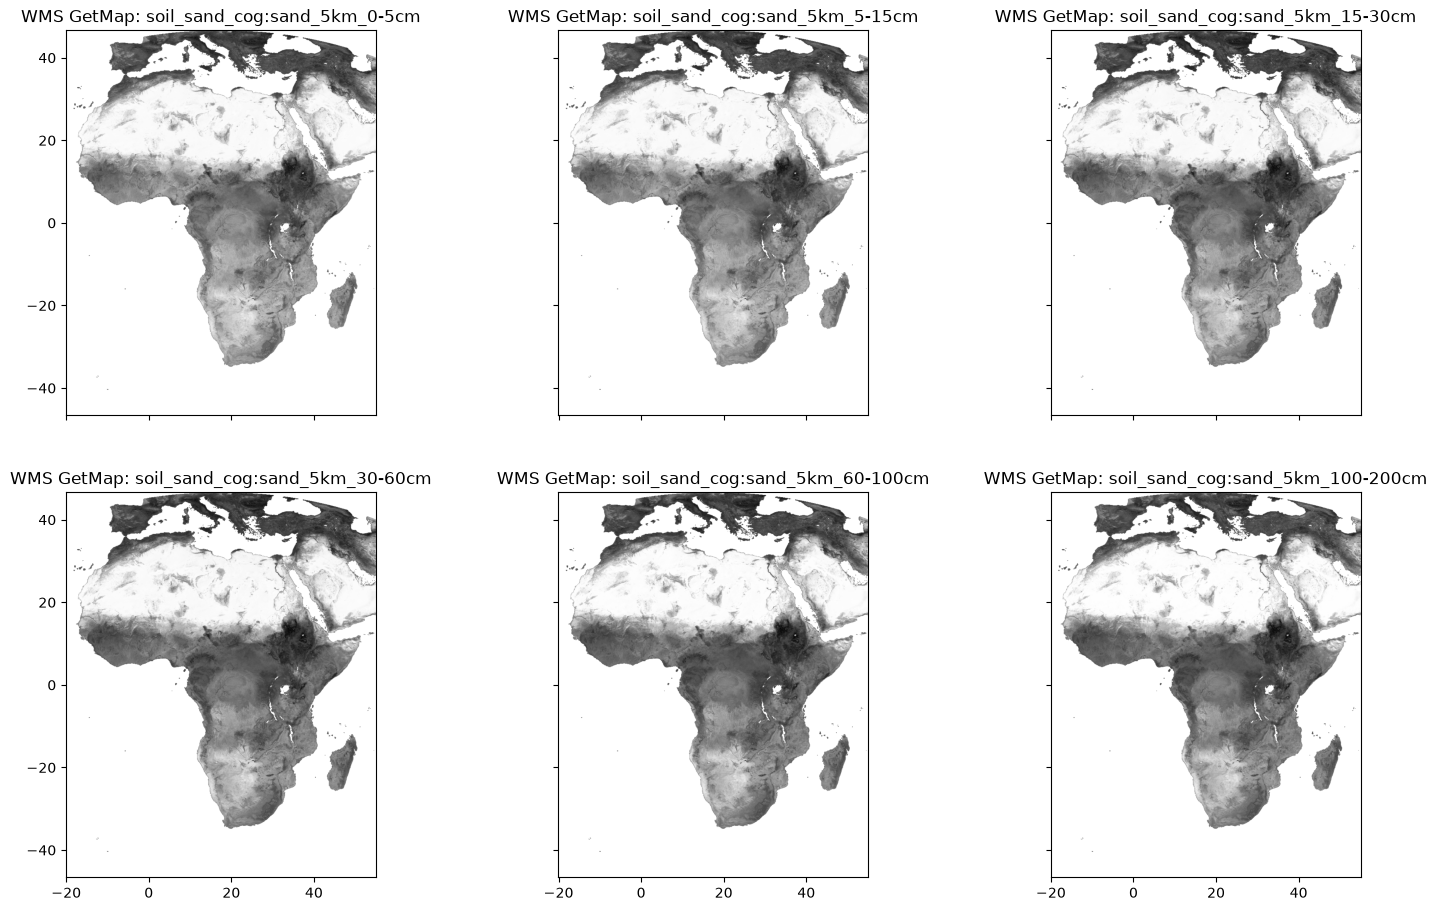

In [16]:
import io
import urllib3
import requests
import matplotlib.image as mpimg

urllib3.disable_warnings()  # the internal GeoServer uses a self-signed certificate

fig, axes = plt.subplots(2, 3, figsize=(18, 11), sharex=True, sharey=True)
for ax, n in zip(axes.ravel(), names):
    # WMS endpoint taken from the STAC item's "visual" asset (added by scripts/28_soil_sand_cog.ipynb)
    wms_url = items[n].assets["visual"].href
    layer = f"{collection_id}:{n}"  # workspace:layer as published in step 8
    print("WMS asset:", wms_url, "| layer:", layer)

    bbox = items[n].bbox
    ny, nx = arrays[(n, "raw (P:)")].shape
    params = dict(
        SERVICE="WMS", VERSION="1.1.1", REQUEST="GetMap", LAYERS=layer, STYLES="",
        SRS="EPSG:4326", BBOX=",".join(str(v) for v in bbox), WIDTH=nx // 2, HEIGHT=ny // 2,
        FORMAT="image/png", TRANSPARENT="true",
    )
    resp = requests.get(wms_url, params=params, verify=False, timeout=60)
    resp.raise_for_status()
    if not resp.headers.get("Content-Type", "").startswith("image"):
        raise RuntimeError(resp.text[:500])  # GeoServer returns XML on errors

    ax.imshow(mpimg.imread(io.BytesIO(resp.content), format="png"), extent=(bbox[0], bbox[2], bbox[1], bbox[3]))
    ax.set_title(f"WMS GetMap: {layer}")
plt.show()